# Lake Como: first look at the simulator

This walkthrough uses **training data only**. Start with the inputs, follow one daily decision, then compare three simple controllers on the same year. These are setup diagnostics, not evidence of generalization.

Select the project's `.venv` Python kernel. The upstream simulator is unchanged.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lake_como.environment import make_env, settings
from lake_como.paths import DAM_DATA, RESULTS
from lake_como.audit import audit
from lake_como.baselines import rollout
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Where the inputs come from

Gym4ReaL bundles annual inflow, demand, and observed-level CSVs plus a minimum environmental flow schedule. The audit checks all seven files and records their hashes. Original measurement provenance and the conflicting paper/metadata data licenses still need resolution.

Leap years contain 366 samples. For reproduction we retain the upstream loader and use its first 365 samples. The horizontal axes below are **simulation days**, not verified calendar dates.

In [2]:
report = audit()
assert not report['errors'], report['errors']
print('Pinned simulator:', report['upstream_commit'])
print(report['calendar_policy'])
params = settings('train')
year = next(iter(params['inflow']))
print('Training years:', len(params['inflow']), '| walkthrough year:', year)
print('Observation order: level, sin(year phase), cos(year phase), recent demand')

Pinned simulator: 774d5ceb1c218e09e5c6458ead7d4b0b10e2d8ac
Reproduce upstream: strip trailing NaN, simulate first 365 samples; leap-year final sample unused. Keep ordinal simulation days, do not claim Gregorian alignment.
Training years: 52 | walkthrough year: 1985
Observation order: level, sin(year phase), cos(year phase), recent demand


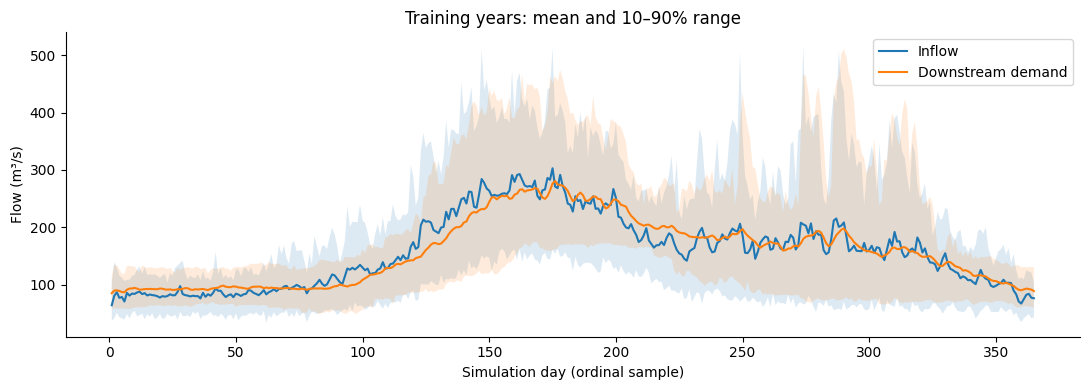

In [3]:
fig, ax = plt.subplots()
for signal, label in [('inflow', 'Inflow'), ('demand', 'Downstream demand')]:
    annual = np.array([v[:365] for v in params[signal].values()])
    ax.plot(np.arange(1, 366), annual.mean(axis=0), label=label)
    ax.fill_between(np.arange(1, 366), *np.quantile(annual, [0.1, 0.9], axis=0), alpha=0.15)
ax.set(xlabel='Simulation day (ordinal sample)', ylabel='Flow (m³/s)', title='Training years: mean and 10–90% range')
ax.legend(); fig.tight_layout()
plt.show()

## One decision, one day

A release request is a rate, in m³/s. Over the day the simulator integrates 24 hourly balances and adjusts the actual release to hydraulic limits. The observation initially contains zero estimated demand; after the first step it includes the first elapsed day's demand.

The water balance uses actual release. Reward combines several penalties; raw physical deficit should be calculated separately because the reward deficit is seasonally weighted.

In [4]:
env = make_env('train', year)
obs, info = env.reset(seed=123)
before = info['storage']
print('Before decision:', obs)
next_obs, reward, terminated, truncated, info = env.step(np.array([100.0], dtype=np.float32))
print('After one day:', next_obs)
print('Requested release: 100 m³/s; actual mean release:', round(info['release'], 3), 'm³/s')
print('New level:', round(info['level'], 3), 'm; reward:', round(reward, 3))
residual = info['storage'] - before - 86400 * (env.unwrapped.inflow[0] - info['release'])
print('Water balance residual:', residual, 'm³')
assert abs(residual) < 1e-4
env.close()

Before decision: [0.35 0.   1.   0.  ]
After one day: [ 0.32080522  0.01721336  0.9998518  16.86      ]
Requested release: 100 m³/s; actual mean release: 100.0 m³/s
New level: 0.321 m; reward: -3.14
Water balance residual: 0.0 m³


/Users/vincentdandenault/Documents/Github/IFT6162_Project/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/Users/vincentdandenault/Documents/Github/IFT6162_Project/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


## Three controllers on the same training year

- **Constant:** request 100 m³/s every day (a diagnostic choice).
- **Random:** sample within nominal action bounds with seed 123.
- **EAD:** request the exponentially averaged past demand.

Each starts at 0.35 m and experiences the same inflow/demand. Their resulting storage trajectories differ. Flood and low-water counts use daily endpoints and do not establish hourly safety.

In [5]:
runs = {policy: rollout(policy, year) for policy in ['constant', 'random', 'ead']}
summary = pd.DataFrame([value[1] for value in runs.values()])
display(summary[['policy', 'return_', 'deficit_m3', 'flood_days', 'low_water_days', 'terminal_storage_m3']].round(2))
assert (summary.steps == 365).all()
assert (summary.max_mass_balance_error_m3 < 1e-4).all()

/Users/vincentdandenault/Documents/Github/IFT6162_Project/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/Users/vincentdandenault/Documents/Github/IFT6162_Project/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(
/Users/vincentdandenault/Documents/Github/IFT6162_Project/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/Users/vincentdandenault/Documents/Github/IFT6162_Project/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(
/Users/vincentdandenault/Documents/Github/IFT616

,policy,return_,deficit_m3,flood_days,low_water_days,terminal_storage_m3
0,constant,-192237.69,6.399424e+08,176,0,52527206.54
1,random,-62593.33,9.639295e+08,30,31,6490511.11
2,ead,-42935.42,4.577958e+08,26,31,9421647.77


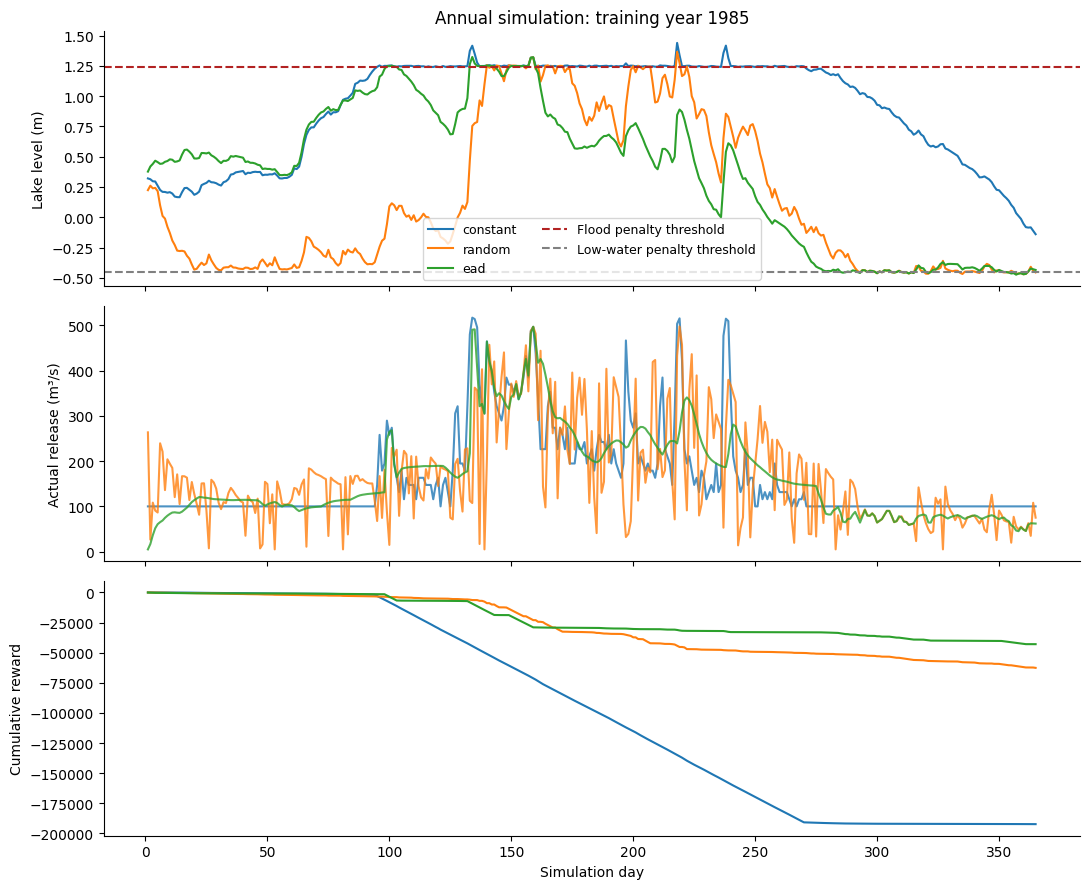

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for policy, (frame, _) in runs.items():
    axes[0].plot(frame.day, frame.level_after_m, label=policy)
    axes[1].plot(frame.day, frame.release_m3_s, label=policy, alpha=0.8)
    axes[2].plot(frame.day, frame.reward.cumsum(), label=policy)
axes[0].axhline(1.24, color='firebrick', linestyle='--', label='Flood penalty threshold')
axes[0].axhline(-0.45, color='gray', linestyle='--', label='Low-water penalty threshold')
axes[0].set(ylabel='Lake level (m)', title=f'Annual simulation: training year {year}')
axes[0].legend(ncol=2, fontsize=9)
axes[1].set(ylabel='Actual release (m³/s)')
axes[2].set(ylabel='Cumulative reward', xlabel='Simulation day')
fig.tight_layout()
RESULTS.mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS / 'baseline_walkthrough.png', dpi=150)
plt.show()

## Observed levels are a separate record

The observed historical level reflects actual historical management and conditions. Our simulation uses our selected controller and a fixed initial level, so it is not expected to reproduce the historical level trace. This overlay illustrates that distinction; it is not a calibrated model-validation result.

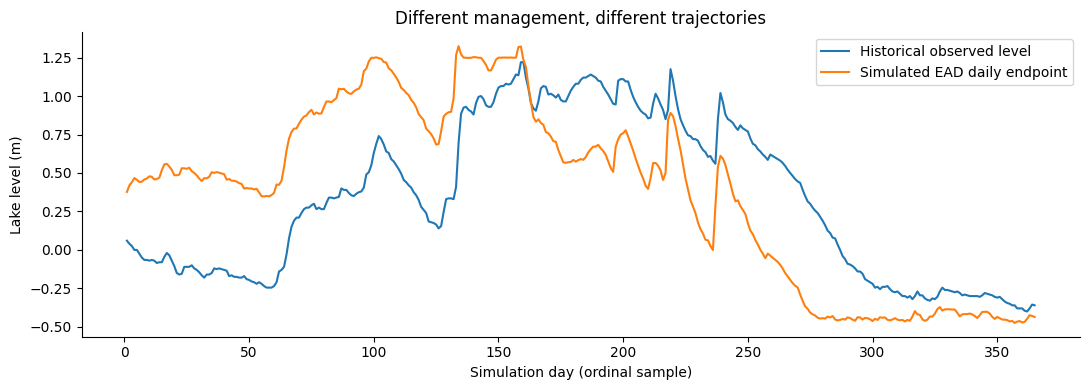

In [7]:
levels = pd.read_csv(DAM_DATA / 'level/water_level_train.csv', index_col='year')
observed = levels.loc[year].dropna().to_numpy()[:365]
fig, ax = plt.subplots()
ax.plot(np.arange(1, 366), observed, label='Historical observed level')
ax.plot(runs['ead'][0].day, runs['ead'][0].level_after_m, label='Simulated EAD daily endpoint')
ax.set(xlabel='Simulation day (ordinal sample)', ylabel='Lake level (m)', title='Different management, different trajectories')
ax.legend(); fig.tight_layout(); plt.show()

## What to inspect together

1. When does a release request differ from the actual release? Look at high/low lake levels.
2. How does a controller trade current demand against future storage?
3. Does better weighted return also improve the physical metrics we care about?
4. What should happen to stored water at the end of an annual episode?

**Known upstream issue:** after the last step, the level in the terminal observation wraps to the initial level. The terminal `info` contains the correct final level/storage, which our metrics use. Future learning code must explicitly handle truncation and terminal-value bootstrapping.

The current calendar behavior and this terminal observation issue are documented for reproduction. Changes to either should be reviewed separately before learning experiments. No learner is trained in this notebook.